In [1]:
%load_ext autoreload
%autoreload 2

import os
from torchvision import models
from torchvision import transforms
from PIL import Image
import torch
import pandas as  pd
import scipy.io as sio
import numpy as np
import glob
import natsort
from scipy.spatial.distance import cdist
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import helperFuns as helper
import cv2
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The module lives one level up from this notebook; add that parent explicitly
module_parent = str(Path.cwd().parent)
if module_parent not in sys.path:
    sys.path.insert(0, module_parent)
    print('Inserted', module_parent, 'into sys.path')
else:
    print('Parent already on sys.path:', module_parent)

# Add the helper functions directory to the path
helper_functions_path = Path(module_parent) / 'helperFunctions' / 'StimulusModeling'
if str(helper_functions_path) not in sys.path:
    sys.path.insert(0, str(helper_functions_path))

import stim_transformations as stf

Inserted /mnt/DataDrive3/emeyer/TreeShrewObjectRecognition into sys.path


In [2]:
img_size = 10
img_type = '.png'
img_set = 'isetbio'
taskName = 'Camel_v2_test_nn' #'Camel_v2_test_nn' 'Camel_Rhino_test_nn' , 'Camel_v2_test_nn', 'Camel_background_matrix'
projectpath = '/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/'
getDataPath = projectpath + '4_treeShrewBehavior/behaviorData/'
camel0 = 0

if taskName == 'Camel_Rhino_test_nn':
    distractor = 'rhino'
else:
    distractor = 'wrench'

img_folder = f'{projectpath}stimulusSets/isettreeshrew/treeshrew_{img_size}/{taskName}_quad/original/merged/'

train_targ_idx, train_dist_idx, _, _, _ = helper.get_train_targdist_data(getDataPath,taskName)

# Load and sort images using natsort
img_files = natsort.natsorted(glob.glob(f'{img_folder}*{img_type}'))
all_names = [os.path.splitext(os.path.basename(img_file))[0].split('_') for img_file in img_files]

Y_labels = [name[0] for name in all_names]
unique_labels = np.unique(Y_labels)

In [3]:
small_ref = cv2.imread(f'{img_folder}camel_4.png', cv2.IMREAD_GRAYSCALE)
large_ref = cv2.imread(f'{img_folder}camel_0.png', cv2.IMREAD_GRAYSCALE)
small_targets = []
large_targets = []
for t_idx in train_targ_idx:
    timg = cv2.imread(f'{img_folder}camel_{int(t_idx)}.png', cv2.IMREAD_GRAYSCALE)
    small_img = stf.transform_image(timg, operation='scale', img_ref = small_ref)
    small_targets.append(small_img)

    large_img = stf.transform_image(timg, operation='scale', img_ref = large_ref)
    large_targets.append(large_img)

small_targets = np.array(small_targets)
large_targets = np.array(large_targets)

In [4]:
nTarg = 100
network = ['alexnet_mouse','alexnet','vgg16']  # 'alexnet_mouse', 'alexnet', 'vgg16'
lay_types = ['ReLU','MaxPool2d','Linear']

# initialize corr_small_large_avg to store average correlations for each layer of each network with different lengths of layers
corr_small_large_avg = [None] * len(network)  # List to hold arrays for each network
for nn_idx, nn in enumerate(network):

    _, model_layers = stf.transform_image(small_ref, operation='NN', layer_types = lay_types, network=nn)
    if nn == 'alexnet_mouse':
        model_layers = ['MaxPool2d: features.3', 'MaxPool2d: features.7', 'ReLU: features.10', 'ReLU: features.13', 'MaxPool2d: features.17', 'Linear: classifier.1', 'Linear: classifier.5']
    elif nn == 'alexnet':
        model_layers = ['MaxPool2d: features.2','MaxPool2d: features.5','ReLU: features.7','ReLU: features.9','MaxPool2d: features.12','Linear: classifier.1','Linear: classifier.4','Linear: classifier.6']
    elif nn == 'vgg16':
        model_layers = ['MaxPool2d: features.4','MaxPool2d: features.9','MaxPool2d: features.16','MaxPool2d: features.23','MaxPool2d: features.30','Linear: classifier.0','Linear: classifier.3','Linear: classifier.6']

    corr_small_large_avg[nn_idx] = np.zeros(len(model_layers))  # Initialize array for this network
    for lay_idx, layers in enumerate(model_layers):
        print(f'Processing {nn} layer {layers}')

        corr_small_large = np.zeros((len(range(nTarg)),1))
        for tt, t_idx in enumerate(range(nTarg)):
            timg = cv2.imread(f'{img_folder}camel_{int(t_idx)}.png', cv2.IMREAD_GRAYSCALE)
            small_img = stf.transform_image(timg, operation='scale', img_ref = small_ref)
            large_img = stf.transform_image(timg, operation='scale', img_ref = large_ref)

            act_small, lay_names = stf.transform_image(small_img, operation='NN', layer_types = layers, network=nn)
            act_small = np.array(act_small[lay_names.index(layers)]).flatten()  # Flatten the activation to a 1D array
            act_large, lay_names = stf.transform_image(large_img, operation='NN', layer_types = layers, network=nn)
            act_large = np.array(act_large[lay_names.index(layers)]).flatten()  # Flatten the activation to a 1D array

            # store correlation between small and large target images for each layer
            if t_idx == 0:
                corr_small_large = np.zeros((len(range(nTarg)),1))
            corr_small_large[tt] = np.corrcoef(act_small, act_large)[0,1]

        # average correlation across all target images for this layer
        corr_small_large_avg[nn_idx][lay_idx] = np.mean(corr_small_large)


Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Processing alexnet_mouse layer MaxPool2d: features.3
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_pool_6. Pretrained: True. Model Family: imagenet.
Loaded parameters from ../mouse_vision/model_ckpts/alexnet_bn_ir.pt
Loading alexnet_bn_ir_64x64_input_p

/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/5_behaviorModeling/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/5_behaviorModeling/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Processing alexnet layer MaxPool2d: features.2
Processing alexnet layer MaxPool2d: features.5
Processing alexnet layer ReLU: features.7
Processing alexnet layer ReLU: features.9
Processing alexnet layer MaxPool2d: features.12
Processing alexnet layer Linear: classifier.1
Processing alexnet layer Linear: classifier.4
Processing alexnet layer Linear: classifier.6


/mnt/DataDrive3/emeyer/TreeShrewObjectRecognition/5_behaviorModeling/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Processing vgg16 layer MaxPool2d: features.4
Processing vgg16 layer MaxPool2d: features.9
Processing vgg16 layer MaxPool2d: features.16
Processing vgg16 layer MaxPool2d: features.23
Processing vgg16 layer MaxPool2d: features.30
Processing vgg16 layer Linear: classifier.0
Processing vgg16 layer Linear: classifier.3
Processing vgg16 layer Linear: classifier.6


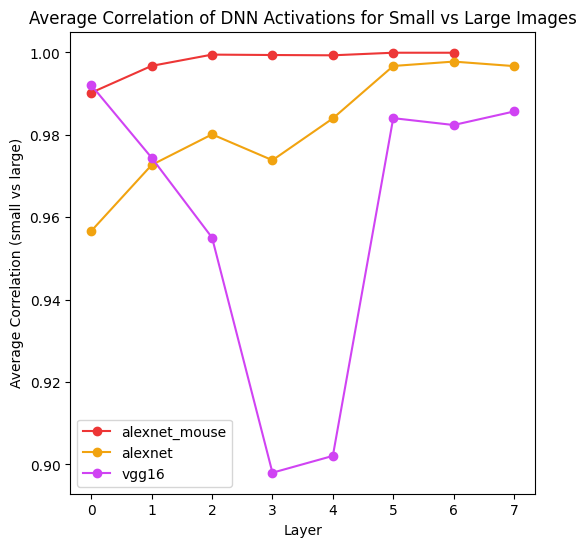

In [6]:
colors = ["#ed3636","#f1a310","#d043f3"]

plt.figure(figsize=(6, 6))
for nn_idx, nn in enumerate(network):
    if nn == 'alexnet_mouse':
        model_layers = ['MaxPool2d: features.3', 'MaxPool2d: features.7', 'ReLU: features.10', 'ReLU: features.13', 'MaxPool2d: features.17', 'Linear: classifier.1', 'Linear: classifier.5']
    elif nn == 'alexnet':
        model_layers = ['MaxPool2d: features.2','MaxPool2d: features.5','ReLU: features.7','ReLU: features.9','MaxPool2d: features.12','Linear: classifier.1','Linear: classifier.4','Linear: classifier.6']
    elif nn == 'vgg16':
        model_layers = ['MaxPool2d: features.4','MaxPool2d: features.9','MaxPool2d: features.16','MaxPool2d: features.23','MaxPool2d: features.30','Linear: classifier.0','Linear: classifier.3','Linear: classifier.6']
    
    plt.plot(range(len(model_layers)),corr_small_large_avg[nn_idx], marker='o', color=colors[nn_idx], label=nn)
plt.xticks(range(len(model_layers)))
plt.xlabel('Layer')
plt.ylabel('Average Correlation (small vs large)')
plt.title('Average Correlation of DNN Activations for Small vs Large Images')
plt.legend()
plt.savefig(f'./figures/{taskName}_corr_small_large_avg.png', dpi=300)
plt.savefig(f'./figures/{taskName}_corr_small_large_avg.svg', dpi=300)
plt.show()